# Análisis exploratorio de datos (EDA) - Dataset Video Game Sales

El dataset Video Game Sales (Gregory Smith, Kaggle: [gregorut/videogamesales](https://www.kaggle.com/datasets/gregorut/videogamesales)) contiene una lista de videojuegos obtenida mediante web scraping del sitio vgchartz.com. Tiene 16.598 registros, con juegos lanzados principalmente entre 1980 y 2016.

Para cada videojuego se registran su posición en el ranking, nombre, plataforma, año, género y editora, además de las ventas en millones de unidades por región:

- Rank: Posición en el ranking de ventas globales
- Name: Nombre del juego
- Platform: Plataforma de lanzamiento (PS2, Wii, PC, etc.)
- Year: Año de lanzamiento
- Genre: Género del juego
- Publisher: Editora
- NA_Sales: Ventas en Norteamérica (millones)
- EU_Sales: Ventas en Europa (millones)
- JP_Sales: Ventas en Japón (millones)
- Other_Sales: Ventas en el resto del mundo (millones)
- Global_Sales: Ventas totales en el mundo (millones)

Objetivos: describir cada variable, comparar los géneros y las regiones, y descubrir qué variables permiten distinguirlos mejor.

![Videojuegos](img/control.jpeg)

## 1. Librerías y carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Cargar Dataset (vgsales.csv debe estar en la misma carpeta del notebook)
data = pd.read_csv('vgsales.csv')
data

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


## 2. Estructura y calidad de los datos

In [3]:
# Tipos de datos, valores no nulos y memoria usada
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  str    
 5   Publisher     16540 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 1.4 MB


In [4]:
# Valores faltantes y registros duplicados
print("Valores nulos por columna:")
print(data.isnull().sum())

print(f"\nRegistros duplicados: {data.duplicated().sum()}")
data[data.duplicated(keep=False)]

Valores nulos por columna:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

Registros duplicados: 0


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales


In [5]:
# Ver cuantos registros hay de cada genero
data['Genre'].value_counts()

Genre
Action          3316
Sports          2346
Misc            1739
Role-Playing    1488
Shooter         1310
Adventure       1286
Racing          1249
Platform         886
Simulation       867
Fighting         848
Strategy         681
Puzzle           582
Name: count, dtype: int64

In [6]:
# Numero de valores unicos en cada columna del dataset
data.nunique()

Rank            16598
Name            11493
Platform           31
Year               39
Genre              12
Publisher         578
NA_Sales          409
EU_Sales          305
JP_Sales          244
Other_Sales       157
Global_Sales      623
dtype: int64

Interpretación: hay 16.598 juegos y 11 columnas. Faltan 271 años y 58 editoras. Los géneros no están balanceados: Action tiene 3.316 juegos y Puzzle 582.

## 3. Estadistica descriptiva

### 3.1 Estadisticas generales

In [7]:
# Muestra media, desviación estándar, mínimo, cuartiles (25% 50% 75%) y máximo
data.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [8]:
# Medidas adicionales rango, rango intercuartílico, coeficiente de variación, asimetría y curtosis
num_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]
num = data[num_cols]

resumen = pd.DataFrame({
    "media": num.mean(),
    "mediana": num.median(),
    "moda": num.mode().iloc[0],
    "desviacion_estandar": num.std(),
    "varianza": num.var(),
    "rango": num.max() - num.min(),
    "IQR": num.quantile(0.75) - num.quantile(0.25),
    "coeficiente de_variacion": num.std() / num.mean() * 100,
    "asimetria": num.skew(),
    "curtosis": num.kurt()
})

resumen

,media,mediana,moda,desviacion_estandar,varianza,rango,IQR,coeficiente de_variacion,asimetria,curtosis
NA_Sales,0.264667,0.08,0.00,0.816683,0.666971,41.49,0.24,308.569524,18.799627,649.130268
EU_Sales,0.146652,0.02,0.00,0.505351,0.255380,29.02,0.11,344.592102,18.875535,756.027796
JP_Sales,0.077782,0.00,0.00,0.309291,0.095661,10.22,0.04,397.639555,11.206458,194.233994
Other_Sales,0.048063,0.01,0.00,0.188588,0.035566,10.57,0.04,392.377350,24.233923,1025.348145
Global_Sales,0.537441,0.17,0.02,1.555028,2.418112,82.73,0.41,289.339468,17.400645,603.932346


Interpretación: la media (0,54 M) es más del triple de la mediana (0,17 M), porque unos pocos juegos venden muchísimo. Por eso la mediana describe mejor al juego típico.

### 3.2 Media, desviación estándar, mínimo y máximo de cada variable por género

In [9]:
data.groupby('Genre')[num_cols].agg(['mean', 'std', 'min', 'max']).round(2).T

Genre              Action  Adventure  Fighting   Misc  Platform  Puzzle  \
NA_Sales     mean    0.26       0.08      0.26   0.24      0.50    0.21   
             std     0.57       0.27      0.52   0.69      1.50    1.06   
             min     0.00       0.00      0.00   0.00      0.00    0.00   
             max     9.63       6.16      6.75  14.97     29.08   23.20   
EU_Sales     mean    0.16       0.05      0.12   0.12      0.23    0.09   
             std     0.41       0.18      0.25   0.45      0.59    0.32   
             min     0.00       0.00      0.00   0.00      0.00    0.00   
             max     9.27       2.79      2.61   9.26      9.23    5.36   
JP_Sales     mean    0.05       0.04      0.10   0.06      0.15    0.10   
             std     0.16       0.12      0.26   0.25      0.53    0.36   
             min     0.00       0.00      0.00   0.00      0.00    0.00   
             max     3.96       2.69      2.87   4.16      6.81    5.32   
Other_Sales  mean    0.06       0.01      0.04   0.04      0.06    0.02   
             std     0.24       0.04      0.11   0.14      0.17    0.07   
             min     0.00       0.00      0.00   0.00      0.00    0.00   
             max    10.57       0.83      1.41   2.85      2.90    1.18   
Global_Sales mean    0.53       0.19      0.53   0.47      0.94    0.42   
             std     1.16       0.51      0.96   1.31      2.59    1.56   
             min     0.01       0.01      0.01   0.01      0.01    0.01   
             max    21.40      11.18     13.04  29.02     40.24   30.26   

Genre              Racing  Role-Playing  Shooter  Simulation  Sports  Strategy  
NA_Sales     mean    0.29          0.22     0.44        0.21    0.29      0.10  
             std     0.74          0.67     1.20        0.47    1.04      0.30  
             min     0.00          0.00     0.00        0.00    0.00      0.00  
             max    15.85         11.27    26.93        9.07   41.49      3.18  
EU_Sales     mean    0.19          0.13     0.24        0.13    0.16      0.07  
             std     0.58          0.49     0.55        0.51    0.78      0.19  
             min     0.00          0.00     0.00        0.00    0.00      0.00  
             max    12.88          8.89     5.88       11.00   29.02      2.27  
JP_Sales     mean    0.05          0.24     0.03        0.07    0.06      0.07  
             std     0.27          0.65     0.10        0.30    0.22      0.17  
             min     0.00          0.00     0.00        0.00    0.00      0.00  
             max     4.13         10.22     1.44        5.33    3.77      1.61  
Other_Sales  mean    0.06          0.04     0.08        0.04    0.06      0.02  
             std     0.27          0.13     0.20        0.12    0.24      0.04  
             min     0.00          0.00     0.00        0.00    0.00      0.00  
             max     7.53          1.74     2.52        2.75    8.46      0.59  
Global_Sales mean    0.59          0.62     0.79        0.45    0.57      0.26  
             std     1.66          1.71     1.82        1.20    2.09      0.52  
             min     0.01          0.01     0.01        0.01    0.01      0.01  
             max    35.82         31.37    28.31       24.76   82.74      5.45

Interpretación: Platform tiene el mayor promedio de ventas por juego (0,94 M) y Adventure el menor (0,19 M).

### 3.3 Variables derivadas (Ingenieria de caracteristicas)

In [10]:
#Nuevas variables a partir de las originales
data["west_sales"] = data["NA_Sales"] + data["EU_Sales"]
data["JP_other_sales"] = data["JP_Sales"] + data["Other_Sales"]

data["NA_ratio"] = data["NA_Sales"] / data["Global_Sales"]
data["JP_ratio"] = data["JP_Sales"] / data["Global_Sales"]

der_cols = ["west_sales", "JP_other_sales", "NA_ratio", "JP_ratio"]
data.groupby('Genre')[der_cols].mean().round(2)

,west_sales,JP_other_sales,NA_ratio,JP_ratio
Genre,,,,
Action,0.42,0.10,0.47,0.20
Adventure,0.13,0.05,0.27,0.52
Fighting,0.38,0.15,0.42,0.35
Misc,0.36,0.11,0.48,0.25
Platform,0.73,0.21,0.57,0.12
Puzzle,0.30,0.12,0.55,0.17
Racing,0.48,0.11,0.54,0.06
Role-Playing,0.35,0.28,0.29,0.50
Shooter,0.68,0.11,0.53,0.08


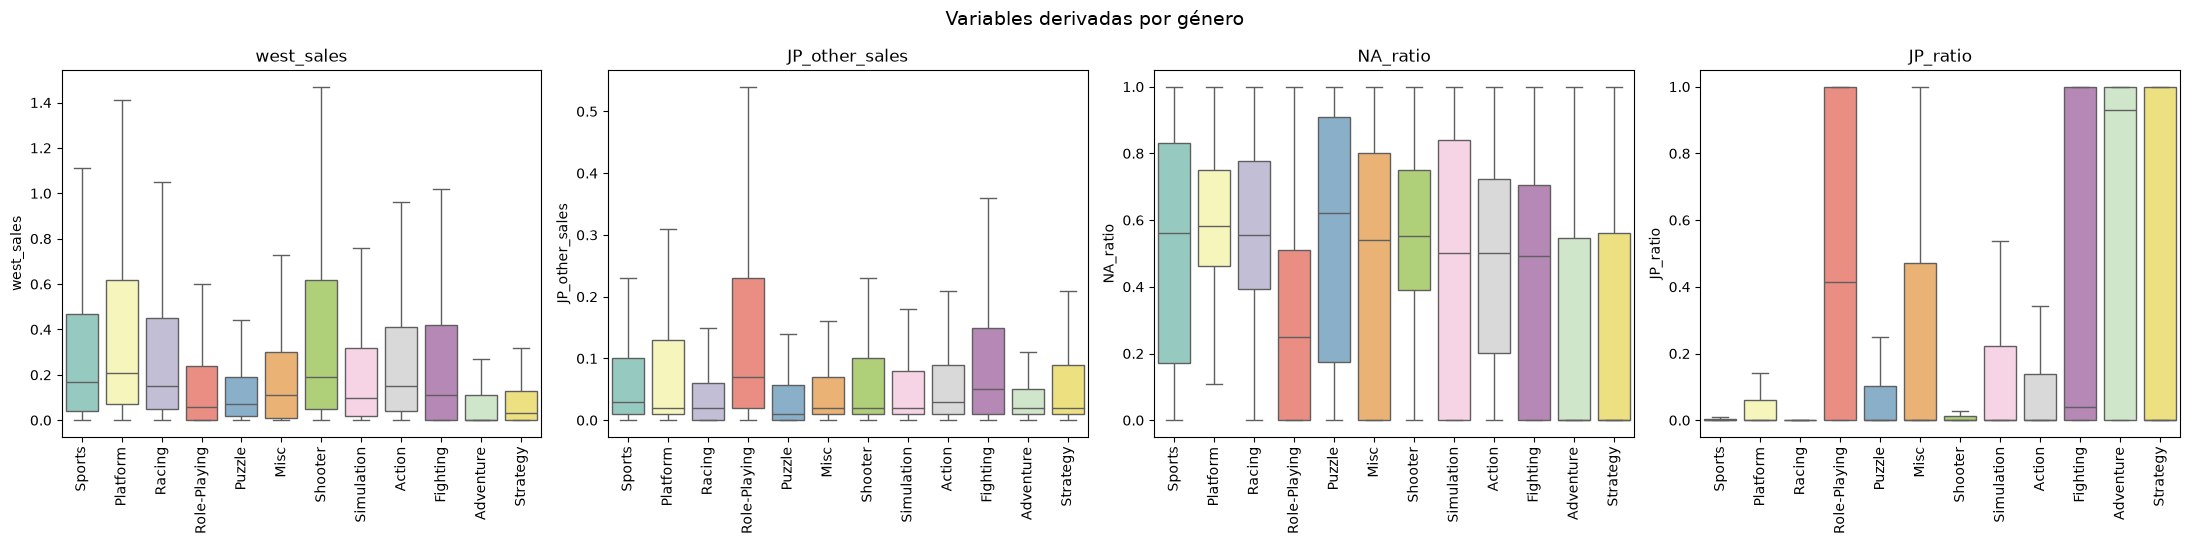

In [11]:
# Diagrama de cajas y bigotes
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))

for ax, col in zip(axes, der_cols):
    sns.boxplot(data=data, x='Genre', y=col, hue='Genre', palette='Set3', legend=False, showfliers=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis='x', rotation=90)

plt.suptitle("Variables derivadas por género", fontsize=14)
plt.tight_layout()
plt.show()

Interpretación: `JP_ratio` es la variable que más separa a los géneros: va de 0,06 en Racing a 0,52 en Adventure. Ese promedio cuenta igual a todos los juegos, así que no es el peso real de Japón (ver sección 4.3). El diagrama no dibuja los valores atípicos para que no aplasten las cajas; se analizan en la sección 3.4.

### 3.4 Valores atípicos (método IQR)

Estrategia investigada. Un valor es atípico si supera el límite superior: Q3 + 1,5 × IQR. Es la misma regla que usan los bigotes del diagrama de cajas.

In [12]:
q1 = num.quantile(0.25) # Primer cuartil
q3 = num.quantile(0.75) # Tercer cuartil
limite = q3 + 1.5 * (q3 - q1) # A partir de aqui un valor es atipico

print("Limite superior:")
print(limite)
print("\nJuegos atipicos:")
print((num > limite).sum())
print("\nPorcentaje de juegos atipicos:")
print(((num > limite).mean() * 100).round(1))

Limite superior:
NA_Sales        0.600
EU_Sales        0.275
JP_Sales        0.100
Other_Sales     0.100
Global_Sales    1.085
dtype: float64

Juegos atipicos:
NA_Sales        1681
EU_Sales        2081
JP_Sales        2425
Other_Sales     1665
Global_Sales    1893
dtype: int64

Porcentaje de juegos atipicos:
NA_Sales        10.1
EU_Sales        12.5
JP_Sales        14.6
Other_Sales     10.0
Global_Sales    11.4
dtype: float64


Interpretación: 1.893 juegos (11,4%) son atípicos en ventas globales, todos por encima de 1,085 M. No se eliminan porque no son errores: son los grandes éxitos.

### 3.5 Correlación entre regiones

Estrategia investigada. Se comparan dos medidas:
- Pearson: mide la relación lineal y se deja influir mucho por los valores extremos.
- Spearman: usa posiciones (quién vende más que quién), así que los superéxitos pesan menos.

In [13]:
print("Correlación de Pearson:")
print(data[num_cols].corr().round(2))

print("\nCorrelación de Spearman:")
print(data[num_cols].corr(method='spearman').round(2))

Correlación de Pearson:
              NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales
NA_Sales          1.00      0.77      0.45         0.63          0.94
EU_Sales          0.77      1.00      0.44         0.73          0.90
JP_Sales          0.45      0.44      1.00         0.29          0.61
Other_Sales       0.63      0.73      0.29         1.00          0.75
Global_Sales      0.94      0.90      0.61         0.75          1.00

Correlación de Spearman:
              NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales
NA_Sales          1.00      0.68     -0.23         0.77          0.80
EU_Sales          0.68      1.00     -0.18         0.77          0.70
JP_Sales         -0.23     -0.18      1.00        -0.07          0.15
Other_Sales       0.77      0.77     -0.07         1.00          0.81
Global_Sales      0.80      0.70      0.15         0.81          1.00


Interpretación: Norteamérica y Europa se mueven juntas (0,77 con Pearson y 0,68 con Spearman). Japón y Norteamérica parecen relacionadas con Pearson (0,45), pero con Spearman la relación es negativa (-0,23): la relación positiva viene de unos pocos superéxitos.

---
# 4. Extensión del análisis: nuevas visualizaciones

Enunciado:

Extender el análisis exploratorio realizado en clase mediante el diseño, generación, interpretación y obtención de conclusiones a partir de al menos tres (3) nuevas visualizaciones que no hayan sido implementadas en la sesión práctica.

Hacer exploración de los datos con las estrategias vistas en clase u otras que se investigue.

Al finalizar adjuntar un video explicando detalladamente el trabajo realizado.

Nota: Incluir también el diagrama de cajas y bigotes.

El diagrama de cajas y bigotes está en la sección 3.3. En clase también se trabajaron la gráfica de línea, la de puntos y la de barras. Esta sección agrega cuatro diagramas que no se hicieron en clase:

- 4.1 Histograma con curva de densidad: ¿Cómo se reparten las ventas?
- 4.2 Curva de Pareto: ¿Cuántos juegos concentran las ventas?
- 4.3 Mapa de calor: ¿Qué género prefiere cada región?
- 4.4 Áreas apiladas: ¿Cómo cambió cada región en el tiempo?

### 4.1 Diagrama 1 — Histograma con curva de densidad: distribución de las ventas globales

Qué muestra: cuántos juegos hay en cada nivel de ventas. El eje horizontal está en escala logarítmica: 10⁻² son 0,01 M, 10⁻¹ son 0,1 M, 10⁰ es 1 M y 10¹ son 10 M.

Por qué: las medidas de la sección 3.1 indican mucha asimetría; esta gráfica permite verla directamente.

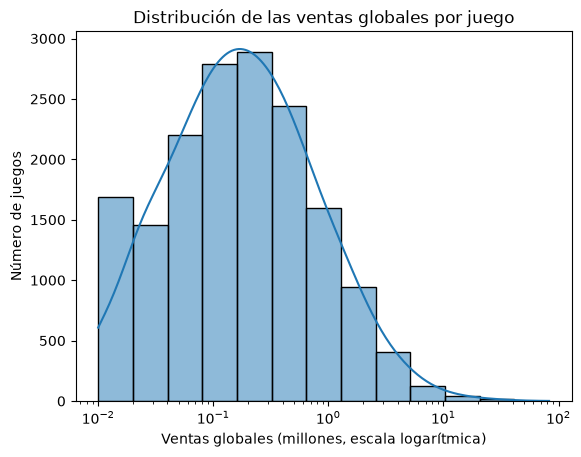

Porcentaje de juegos con menos de 1 millón: 87.5
Juegos con 10 millones o más: 62


In [14]:
sns.histplot(data=data, x='Global_Sales', bins=13, log_scale=True, kde=True, kde_kws={'bw_adjust': 2})
plt.title("Distribución de las ventas globales por juego")
plt.xlabel("Ventas globales (millones, escala logarítmica)")
plt.ylabel("Número de juegos")
plt.show()

print("Porcentaje de juegos con menos de 1 millón:", round((data['Global_Sales'] < 1).mean() * 100, 1))
print("Juegos con 10 millones o más:", (data['Global_Sales'] >= 10).sum())

Interpretación: el 87,5% de los juegos vendió menos de 1 millón y solo 62 llegaron a 10 millones. Con la escala logarítmica la forma se ve casi simétrica.

### 4.2 Diagrama 2 — Curva de Pareto: concentración de las ventas

Qué muestra: se ordenan los juegos de mayor a menor venta y se acumula el porcentaje de ventas. Por ejemplo, un punto en (20, 75) significa que el 20% de los juegos más vendidos genera el 75% de las ventas.

Por qué: la regla de Pareto (80/20) es una herramienta típica de inteligencia de negocios para saber si unos pocos productos generan casi todo el resultado.

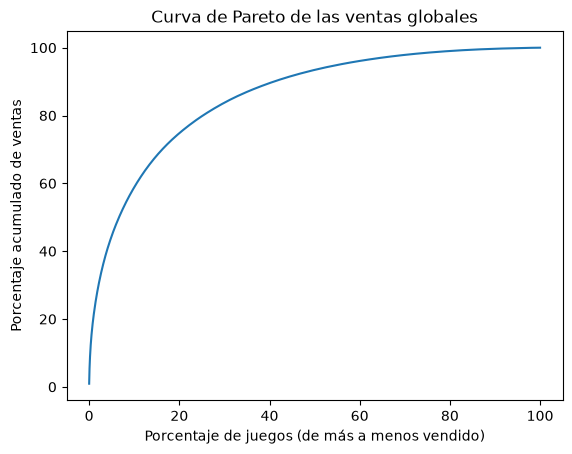

Ventas que genera el 1% de los juegos: 21.1
Ventas que genera el 20% de los juegos: 74.8


In [15]:
ventas = data['Global_Sales'].sort_values(ascending=False) # Juegos de mayor a menor venta
pct_ventas = ventas.cumsum() / ventas.sum() * 100 # Porcentaje acumulado de las ventas
pct_juegos = np.arange(1, len(ventas) + 1) / len(ventas) * 100 # Porcentaje acumulado de los juegos

plt.plot(pct_juegos, pct_ventas)
plt.title("Curva de Pareto de las ventas globales")
plt.xlabel("Porcentaje de juegos (de más a menos vendido)")
plt.ylabel("Porcentaje acumulado de ventas")
plt.show()

print("Ventas que genera el 1% de los juegos:", pct_ventas.iloc[len(ventas) // 100].round(1))
print("Ventas que genera el 20% de los juegos:", pct_ventas.iloc[len(ventas) // 5].round(1))

Interpretación: el 20% de los juegos genera el 74,8% de las ventas y el 1% genera el 21,1%. El resultado depende de pocos títulos.

### 4.3 Diagrama 3 — Mapa de calor: proporción de las ventas de cada género por región

Qué muestra: de todas las ventas de cada género, qué proporción viene de cada región. Cada fila suma 1; entre más oscuro el color, mayor la proporción.

Por qué: para saber qué tipo de juegos prefiere cada región. A diferencia de JP_ratio (sección 3.3), aquí cada juego pesa según lo que realmente vendió.

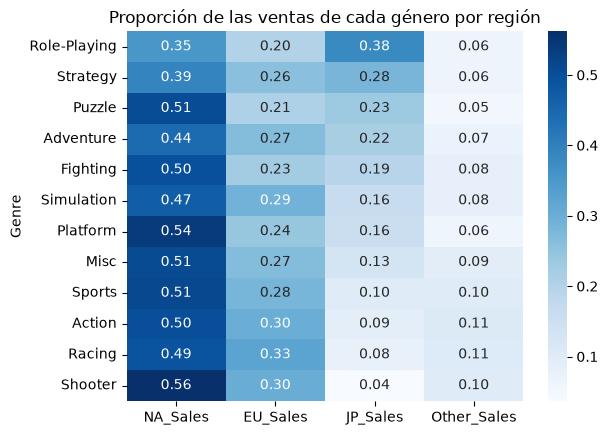

Porcentaje de cada región en el total de ventas:
NA_Sales       49.3
EU_Sales       27.3
JP_Sales       14.5
Other_Sales     8.9
dtype: float64


In [16]:
reg_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"] # Columnas de las regiones
genero_region = data.groupby('Genre')[reg_cols].sum() # Ventas de cada region por genero
proporcion = genero_region.div(genero_region.sum(axis=1), axis=0) # Cada fila suma 1

sns.heatmap(proporcion.sort_values('JP_Sales', ascending=False), annot=True, fmt='.2f', cmap='Blues')
plt.title("Proporción de las ventas de cada género por región")
plt.show()

print("Porcentaje de cada región en el total de ventas:")
print((genero_region.sum() / genero_region.sum().sum() * 100).round(1))

In [17]:
# Comparar el promedio de JP_ratio con el peso real de Japon en las ventas
pd.DataFrame({
    "JP_ratio_promedio": data.groupby('Genre')['JP_ratio'].mean(),
    "peso_real_Japon": proporcion['JP_Sales']
}).sort_values('peso_real_Japon', ascending=False).round(2)

,JP_ratio_promedio,peso_real_Japon
Genre,,
Role-Playing,0.50,0.38
Strategy,0.33,0.28
Puzzle,0.17,0.23
Adventure,0.52,0.22
Fighting,0.35,0.19
Simulation,0.22,0.16
Platform,0.12,0.16
Misc,0.25,0.13
Sports,0.17,0.10


Interpretación: Norteamérica aporta el 49,3% de las ventas. Role-Playing es el único género donde Japón (0,38) supera a Norteamérica (0,35). En Adventure Japón pesa 0,22, aunque su JP_ratio promedio es 0,52: muchos juegos pequeños venden casi solo allá, pero los grandes venden en Occidente.

### 4.4 Diagrama 4 — Áreas apiladas: ventas por región según el año de lanzamiento

Qué muestra: el alto total es lo que vendieron los juegos lanzados cada año, y cada franja es el aporte de una región. No son las ventas ocurridas en ese año: un juego de 2008 acumula aquí todas sus ventas, sean del año que sean.

Por qué: para ver cuándo fue el mejor momento de la industria y cómo cambió el peso de cada región.

Filtro: se usan los juegos hasta 2015. Se excluyen los que no tienen año y los de 2016 en adelante, porque esos años están incompletos: 2016 tiene 344 juegos frente a 614 en 2015, y de 2017 y 2020 solo hay 4.

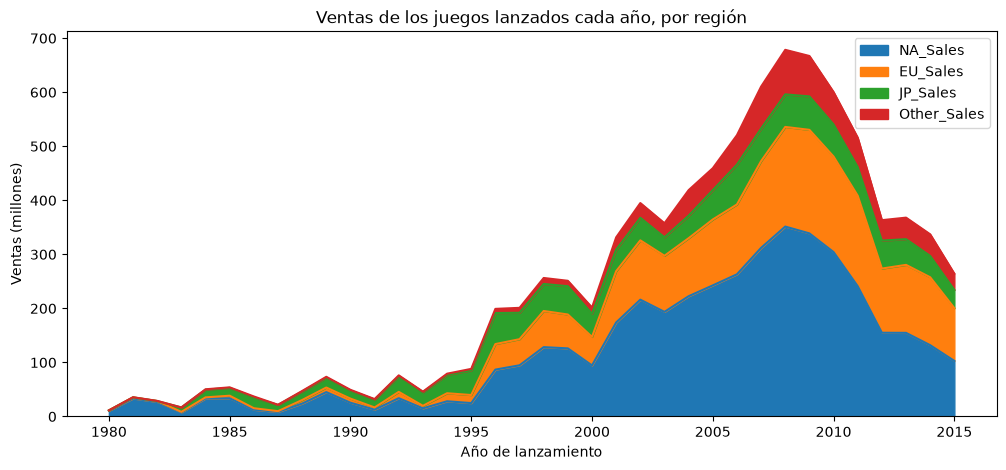

Años con más ventas:
Year
2008.0    678.9
2009.0    667.3
2007.0    611.1
Name: Global_Sales, dtype: float64


In [18]:
tiempo = data[data['Year'] <= 2015] # Quita los juegos sin año y los años incompletos
por_anio = tiempo.groupby('Year')[reg_cols].sum() # Ventas de cada region por año

por_anio.plot.area(figsize=(12, 5)) # Una franja por region
plt.title("Ventas de los juegos lanzados cada año, por región")
plt.xlabel("Año de lanzamiento")
plt.ylabel("Ventas (millones)")
plt.show()

print("Años con más ventas:")
print(tiempo.groupby('Year')['Global_Sales'].sum().nlargest(3).round(1))

In [19]:
# Porcentaje de las ventas de cada region en cada decada
decada = tiempo['Year'] // 10 * 10 # 1994 se convierte en 1990
por_decada = tiempo.groupby(decada)[reg_cols].sum()
(por_decada.div(por_decada.sum(axis=1), axis=0) * 100).round(1)

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Year,,,,
1980.0,62.6,8.3,27.2,1.9
1990.0,45.1,22.1,29.1,3.7
2000.0,51.9,27.1,11.0,10.0
2010.0,44.5,33.2,11.6,10.7


Interpretación: las ventas llegan a su máximo con los juegos lanzados en 2008 (678,9 M) y 2009 (667,3 M). Japón bajó de cerca del 29% en los 90 a cerca del 11% en los 2000, y Europa subió del 22% al 27%.

## 5. Conclusiones

1. Ventas concentradas: el 20% de los juegos genera cerca del 75% de las ventas.
2. Géneros: Platform tiene la mejor venta promedio por juego (0,94 M) y Adventure la menor (0,19 M).
3. Regiones: Norteamérica es el mercado principal (49,3%). Japón es el más diferente: Role-Playing es el único género donde supera a Norteamérica.
4. Tiempo: los juegos lanzados en 2008 y 2009 son los que más vendieron, y Japón perdió peso frente a Europa.

Recomendación: adaptar cada juego a su región: Role-Playing pensando en Japón, y Shooter o Racing pensando en Norteamérica y Europa.

Limitaciones: las ventas son estimaciones de vgchartz.com y los años desde 2016 están incompletos.